## Part A — demonstrate overfitting (the deliverable's core)

## TASK 01 Polynomial regression at degrees 1, 5, 15

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# 1. Load California Housing dataset
df = pd.read_csv("california_housing.csv")

# Use your actual column names
df = df[["MedInc", "MedHouseVal"]].dropna()

X = df[["MedInc"]]
y = df["MedHouseVal"]

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Fit polynomial regression for degrees 1, 5, and 15
degrees = [1, 5, 15]
results = []

X_plot = pd.DataFrame({
    "MedInc": np.linspace(X["MedInc"].min(), X["MedInc"].max(), 500)
})

plt.figure(figsize=(12, 7))

# Plot a sample of the actual observations
plt.scatter(
    X_test["MedInc"], y_test,
    alpha=0.25, s=10, label="Actual test data"
)

for degree in degrees:

    # Create polynomial regression model
    model = Pipeline([
        ("scale", StandardScaler()),
        ("poly", PolynomialFeatures(
            degree=degree, include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    # Train model
    model.fit(X_train, y_train)

    # Calculate training and testing predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Calculate errors
    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    # Save results
    results.append({
        "Degree": degree,
        "Training MSE": train_mse,
        "Testing MSE": test_mse
    })

    # Plot fitted curve
    y_plot = model.predict(X_plot)

    plt.plot(
        X_plot["MedInc"], y_plot,
        linewidth=2, label=f"Degree {degree}"
    )

# 4. Display graph
plt.xlabel("Median Income (MedInc)")
plt.ylabel("Median House Value (MedHouseVal)")
plt.title("Polynomial Regression: Degrees 1, 5, and 15")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Print training and testing errors
results_df = pd.DataFrame(results)

print("\nTraining and Testing Errors:")
print(results_df.to_string(index=False, float_format="%.6f"))

# 6. Identify the model with the lowest testing error
best_degree = results_df.loc[
    results_df["Testing MSE"].idxmin(), "Degree"
]

print(f"\nDegree with lowest testing MSE: {best_degree}")

# 7. Compare training and testing errors
print("\nModel interpretation:")

for _, row in results_df.iterrows():
    degree = int(row["Degree"])
    train_error = row["Training MSE"]
    test_error = row["Testing MSE"]

    print(
        f"Degree {degree}: "
        f"Training MSE = {train_error:.6f}, "
        f"Testing MSE = {test_error:.6f}"
    )

print(
    "\nNote: Lower training error alone does not prove overfitting. "
    "Compare training and testing errors to assess generalization. "
    "The true underlying curve is unknown for real California Housing data."
)

**1. Why can training error alone never tell you a model is overfitting?**  
Training error measures performance on data the model has already seen. We need test error to determine whether the model generalizes well to unseen data.

**2. What specifically about degree 15's fit signals memorization rather than learning?**  
Degree 15 may have very low training error but much higher test error, indicating that it has learned noise and specific training patterns instead of general relationships.

**3. If you had less noise in your data, would degree 15 overfit as badly? Why or why not?**  
Probably not as badly, because less noise reduces the chance of fitting random patterns. However, degree 15 could still overfit due to its high complexity.

## TASK 02 The bias-variance curve

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# 1. Load the California Housing dataset
df = pd.read_csv("california_housing.csv")

# 2. Select input features and target column
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# 3. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Store training and testing errors
degrees = range(1, 16)
train_errors = []
test_errors = []

# 5. Train polynomial regression models for degrees 1 to 15
for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict on training and testing data
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate Mean Squared Error
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    train_errors.append(train_mse)
    test_errors.append(test_mse)

    print(
        f"Degree {degree:2d} | "
        f"Train MSE: {train_mse:.4f} | "
        f"Test MSE: {test_mse:.4f}"
    )

# 6. Identify the degree with the lowest test error
best_index = np.argmin(test_errors)
best_degree = list(degrees)[best_index]
best_test_error = test_errors[best_index]

print("\nBest Polynomial Degree:", best_degree)
print("Lowest Test MSE:", round(best_test_error, 4))

# 7. Plot training and testing error curves
plt.figure(figsize=(10, 6))

plt.plot(list(degrees), train_errors, marker="o", label="Training MSE")

plt.plot(list(degrees), test_errors, marker="o", label="Testing MSE")

# Highlight the best degree
plt.scatter(
    best_degree, best_test_error,
    color="red", s=120, zorder=5,
    label=f"Best Degree: {best_degree}"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("California Housing: Training vs Testing Error")
plt.xticks(list(degrees))
plt.legend()
plt.grid(True)
plt.show()

1\. Why does training error almost always keep falling, but test error doesn't?\
As model complexity increases, the model fits training data better, but it may learn noise and overfit. Therefore, test error can increase on unseen data.

2\. Is the sweet spot always the same for every dataset? What would change it?\
No, it depends on the dataset's size, noise level, feature relationships, and model choice. These factors affect which degree generalizes best.

3\. How is this curve different from—or the same as—the loss-vs-training-step curves from Day 21?\
Both curves track model error. The bias–variance curve compares training and test errors across model degrees, while the Day 21 curve tracks loss across training steps to show how the model learns.

## Part B — Ridge, Lasso, and Elastic Net on real data

## TASK 03 Apply all three regularizers 


In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

# 1. Load California Housing dataset
df = pd.read_csv("california_housing.csv")

# 2. Select features and target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# 3. Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Define models and regularization strengths
models = [
    ("Linear Regression", "None", LinearRegression()),
    ("Ridge", 0.1, Ridge(alpha=0.1)),
    ("Ridge", 1.0, Ridge(alpha=1.0)),
    ("Ridge", 10.0, Ridge(alpha=10.0)),
    ("Lasso", 0.01, Lasso(alpha=0.01, max_iter=10000)),
    ("Lasso", 0.1, Lasso(alpha=0.1, max_iter=10000)),
    ("Lasso", 1.0, Lasso(alpha=1.0, max_iter=10000)),
    ("Elastic Net", 0.01, ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)),
    ("Elastic Net", 0.1, ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)),
    ("Elastic Net", 1.0, ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000))
]

# 6. Train models and collect results
results = []

for name, strength, model in models:
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    test_r2 = r2_score(y_test, y_pred)

    # Count exactly zero coefficients
    zero_coefficients = np.sum(model.coef_ == 0)

    results.append({
            "Model": name,
            "Alpha": strength,
            "Test R2": round(test_r2, 4),
            "Exactly Zero Coefficients": zero_coefficients
    })

# 7. Display results in one table
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

            Model Alpha  Test R2  Exactly Zero Coefficients
Linear Regression  None   0.8383                          0
            Ridge   0.1   0.8383                          0
            Ridge   1.0   0.8383                          0
            Ridge  10.0   0.8385                          0
            Lasso  0.01   0.8383                          2
            Lasso   0.1   0.7902                          3
            Lasso   1.0  -0.0000                          8
      Elastic Net  0.01   0.8388                          2
      Elastic Net   0.1   0.8218                          3
      Elastic Net   1.0   0.3686                          7


1\. Does adding regularization always improve test R²?

 When might it make it worse?\
No, regularization does not always improve test R². Too much regularization can shrink important coefficients excessively, causing underfitting and lower test R².

2\. Why is scaling the features especially important before Ridge or Lasso, more so than for plain linear regression?\

Ridge and Lasso penalize coefficient sizes, so features on different scales can be penalized unfairly. Scaling puts features on comparable scales, making regularization more balanced.

3\. If two models have similar R² but very different numbers of zero coefficients, which would you prefer, and why?\

I would prefer the model with more zero coefficients if interpretability and simplicity are important, because it uses fewer features while maintaining similar predictive performance.

## TASK 04 Prove Lasso does feature selection

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# 1. Load California Housing dataset
df = pd.read_csv("california_housing.csv")

# 2. Separate features and target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

feature_names = X.columns

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Scale features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 5. Test different alpha values
alphas = np.logspace(-3, 0, 20)

first_zero_alpha = None
first_zero_feature = None
one_feature_alpha = None
last_surviving_feature = None

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)

    # Find features whose coefficients are exactly zero
    dropped = [
        feature for feature, coef
        in zip(feature_names, lasso.coef_)
        if coef == 0
    ]

    # Find features whose coefficients are not zero
    surviving = [
        feature for feature, coef
        in zip(feature_names, lasso.coef_)
        if coef != 0
    ]

    print(f"\nAlpha: {alpha:.5f}")
    print("Zeroed-out features:", dropped if dropped else "None")
    print("Surviving features:", surviving if surviving else "None")

    # Record the first alpha at which any feature becomes zero
    if first_zero_alpha is None and dropped:
        first_zero_alpha = alpha
        first_zero_feature = dropped[0]

    # Record the first alpha at which only one feature survives
    if one_feature_alpha is None and len(surviving) == 1:
        one_feature_alpha = alpha
        last_surviving_feature = surviving[0]

# 6. Print assignment answers
print("\nFINAL RESULTS ")

if first_zero_alpha is not None:
    print("First feature zeroed:", first_zero_feature)
    print("Alpha at first zero:", round(first_zero_alpha, 5))
else:
    print("No feature became exactly zero in this alpha range.")

if one_feature_alpha is not None:
    print("Alpha with one feature remaining:", round(one_feature_alpha, 5))
    print("Last surviving feature:", last_surviving_feature)
else:
    print("Only one surviving feature was not reached in this alpha range.")


Alpha: 0.00100
Zeroed-out features: None
Surviving features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alpha: 0.00144
Zeroed-out features: None
Surviving features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alpha: 0.00207
Zeroed-out features: ['AveBedrms']
Surviving features: ['MedInc', 'HouseAge', 'AveRooms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alpha: 0.00298
Zeroed-out features: ['AveBedrms', 'Population']
Surviving features: ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

Alpha: 0.00428
Zeroed-out features: ['AveBedrms', 'Population']
Surviving features: ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

Alpha: 0.00616
Zeroed-out features: ['AveBedrms', 'Population']
Surviving features: ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

Alpha: 0.00886
Zeroed-out features: ['AveBedrms',

**1. Why might the feature that survives longest be the one with the strongest correlation to the target?**  
A feature strongly related to the target often provides more predictive information, so Lasso may retain its coefficient even when regularization increases.

**2. Could two equally useful features compete and one get dropped somewhat arbitrarily? When?**  
Yes, when two features are highly correlated and provide similar information, Lasso may keep one and shrink the other's coefficient to zero.

**3. How would you use this feature-dropping order to decide which features to actually collect in a real project?**  
I would prioritize features that consistently remain useful, then evaluate model performance without the dropped features and consider collection cost, reliability, and business value before deciding which features to keep.


## Part C — the geometry, the paths, and honest tuning

## TASK 05 Explain the L1 vs L2 geometry in your own words

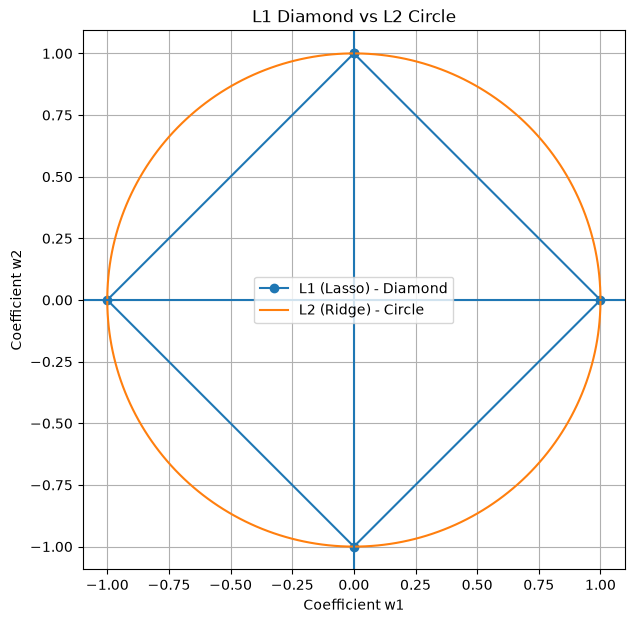

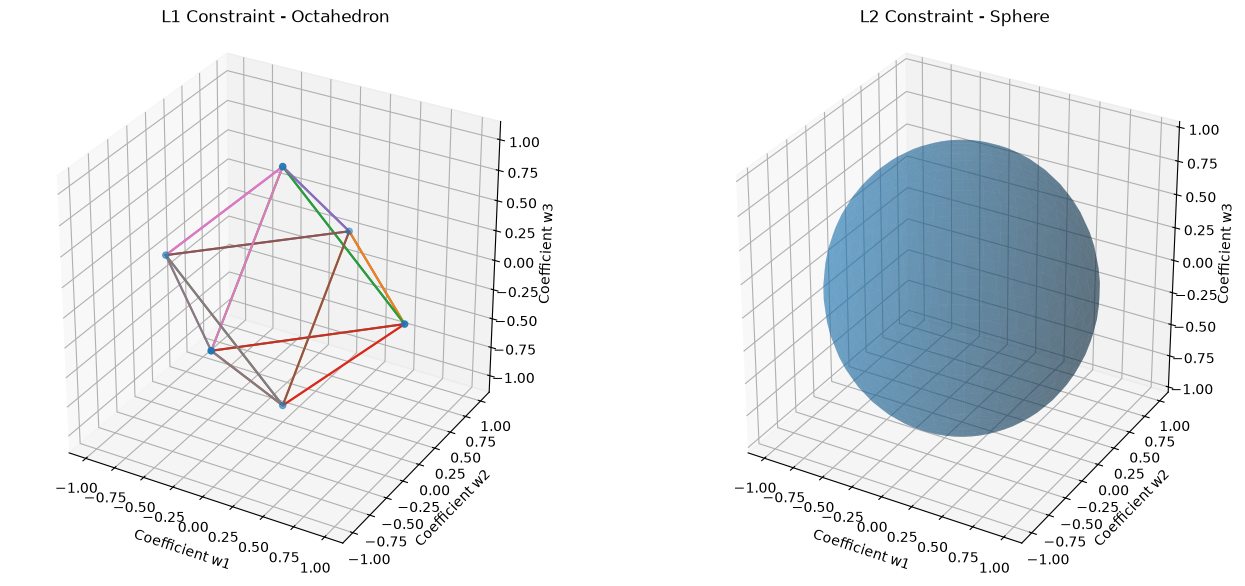

2D L1 diamond: 4 corners
3D L1 octahedron: 6 corners (vertices)
3D L1 octahedron: 8 triangular faces


In [6]:
import numpy as np
import matplotlib.pyplot as plt


# PART 1: L1 Diamond vs L2 Circle (2D)

theta = np.linspace(0, 2 * np.pi, 500)

# L1 diamond: |w1| + |w2| = 1
l1_x = [0, 1, 0, -1, 0]
l1_y = [1, 0, -1, 0, 1]

# L2 circle: w1² + w2² = 1
l2_x = np.cos(theta)
l2_y = np.sin(theta)

plt.figure(figsize=(7, 7))
plt.plot(l1_x, l1_y, marker="o", label="L1 (Lasso) - Diamond")
plt.plot(l2_x, l2_y, label="L2 (Ridge) - Circle")

plt.xlabel("Coefficient w1")
plt.ylabel("Coefficient w2")
plt.title("L1 Diamond vs L2 Circle")
plt.axhline(0)
plt.axvline(0)
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


# PART 2: L1 Octahedron vs L2 Sphere (3D)

fig = plt.figure(figsize=(14, 6))

# Six vertices of the L1 octahedron
vertices = np.array([
    [1, 0, 0],
    [-1, 0, 0],
    [0, 1, 0],
    [0, -1, 0],
    [0, 0, 1],
    [0, 0, -1]
])

# Eight triangular faces
faces = [
    [0, 2, 4], [0, 2, 5],
    [0, 3, 4], [0, 3, 5],
    [1, 2, 4], [1, 2, 5],
    [1, 3, 4], [1, 3, 5]
]

ax1 = fig.add_subplot(121, projection="3d")

for face in faces:
    triangle = vertices[face]
    triangle = np.vstack([triangle, triangle[0]])

    ax1.plot(
        triangle[:, 0],
        triangle[:, 1],
        triangle[:, 2]
    )

ax1.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2])

ax1.set_title("L1 Constraint - Octahedron")
ax1.set_xlabel("Coefficient w1")
ax1.set_ylabel("Coefficient w2")
ax1.set_zlabel("Coefficient w3")
ax1.set_box_aspect((1, 1, 1))


# Draw the L2 sphere
ax2 = fig.add_subplot(122, projection="3d")

u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 30)

x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones_like(u), np.cos(v))

ax2.plot_surface(x, y, z, alpha=0.4)

ax2.set_title("L2 Constraint - Sphere")
ax2.set_xlabel("Coefficient w1")
ax2.set_ylabel("Coefficient w2")
ax2.set_zlabel("Coefficient w3")
ax2.set_box_aspect((1, 1, 1))

plt.tight_layout()
plt.show()

print("2D L1 diamond: 4 corners")
print("3D L1 octahedron: 6 corners (vertices)")
print("3D L1 octahedron: 8 triangular faces")

Why L1 and L2 Produce different coefficients?

L1 regularization (Lasso) has a diamond-shaped constraint region in two dimensions, with sharp corners lying on the coefficient axes. When the model's error contours touch this region, they can meet at a corner where one or more coefficients are exactly zero. This allows Lasso to remove less useful features automatically. In contrast, L2 regularization (Ridge) has a smooth, circular boundary with no sharp corners, so the solution usually has small but nonzero coefficients. Therefore, L1 can perform feature selection, while L2 generally shrinks coefficients without removing features completely.

1. **Why does a contour line touch an L1 corner?**  
   L1 has sharp corners on the coefficient axes. Error contours can touch these corners, where one or more coefficients are exactly zero, helping Lasso eliminate features.

2. **What happens to corners as dimensions increase?**  
   The number of corners increases exponentially. With \(n\) features, the L1 shape has \(2^n\) corners. For example, 3 features have 8?

## TASK 06 Coefficient paths and honest tuning

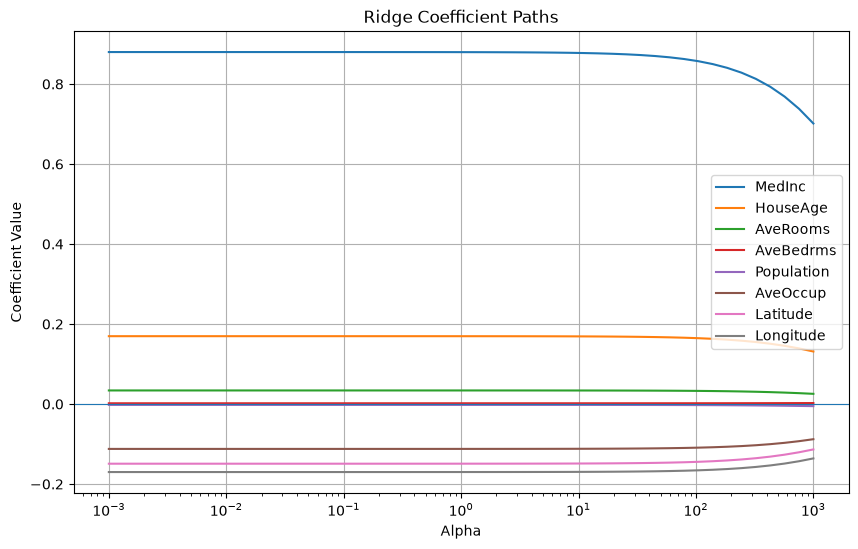

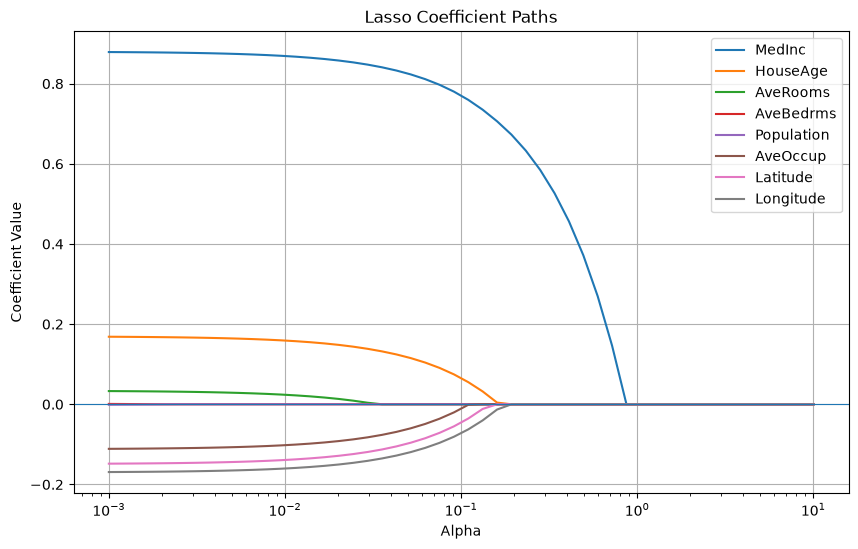

Selected alpha values:
RidgeCV alpha: 3.5564803062231287
LassoCV alpha: 0.002559547922699536

Test R2 comparison:
         Model   Alpha Test R2
Ridge - Manual 1.00000  0.8383
       RidgeCV 3.55648  0.8384
Lasso - Manual 0.10000  0.7902
       LassoCV 0.00256  0.8385

Absolute difference in test R2:
Ridge: 0.0001
Lasso: 0.0483


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import r2_score

# 1. Load California Housing CSV
df = pd.read_csv("california_housing.csv")

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
feature_names = X.columns

# 2. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define alpha ranges
ridge_alphas = np.logspace(-3, 3, 50)
lasso_alphas = np.logspace(-3, 1, 50)

# 5. Ridge coefficient path
ridge_coefs = []

for alpha in ridge_alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    ridge_coefs.append(model.coef_)

ridge_coefs = np.array(ridge_coefs)

plt.figure(figsize=(10, 6))
for i, feature in enumerate(feature_names):
    plt.plot(ridge_alphas, ridge_coefs[:, i], label=feature)

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficient Paths")
plt.axhline(0, linewidth=0.8)
plt.legend()
plt.grid(True)
plt.show()

# 6. Lasso coefficient path
lasso_coefs = []

for alpha in lasso_alphas:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    lasso_coefs.append(model.coef_)

lasso_coefs = np.array(lasso_coefs)

plt.figure(figsize=(10, 6))
for i, feature in enumerate(feature_names):
    plt.plot(lasso_alphas, lasso_coefs[:, i], label=feature)

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("Lasso Coefficient Paths")
plt.axhline(0, linewidth=0.8)
plt.legend()
plt.grid(True)
plt.show()

# 7. Select alpha using 5-fold cross-validation
ridge_cv = RidgeCV(alphas=ridge_alphas, cv=5)
ridge_cv.fit(X_train_scaled, y_train)

lasso_cv = LassoCV(alphas=lasso_alphas, cv=5, max_iter=10000)
lasso_cv.fit(X_train_scaled, y_train)

# 8. Evaluate cross-validation models on test data
ridge_cv_r2 = r2_score( y_test, ridge_cv.predict(X_test_scaled))

lasso_cv_r2 = r2_score(y_test, lasso_cv.predict(X_test_scaled))

# 9. Compare with manually selected alpha values from Task 3
# Replace these with your actual best alpha values from Task 3.
manual_ridge_alpha = 1.0
manual_lasso_alpha = 0.1

manual_ridge = Ridge(alpha=manual_ridge_alpha)
manual_ridge.fit(X_train_scaled, y_train)

manual_lasso = Lasso(alpha=manual_lasso_alpha, max_iter=10000)
manual_lasso.fit(X_train_scaled, y_train)

manual_ridge_r2 = r2_score(
    y_test, manual_ridge.predict(X_test_scaled)
)

manual_lasso_r2 = r2_score(
    y_test, manual_lasso.predict(X_test_scaled)
)

# 10. Display comparison table
results = pd.DataFrame({
    "Model": [
        "Ridge - Manual",
        "RidgeCV",
        "Lasso - Manual",
        "LassoCV"
    ],
    "Alpha": [
        manual_ridge_alpha,
        ridge_cv.alpha_,
        manual_lasso_alpha,
        lasso_cv.alpha_
    ],
    "Test R2": [
        manual_ridge_r2,
        ridge_cv_r2,
        manual_lasso_r2,
        lasso_cv_r2
    ]
})

print("Selected alpha values:")
print("RidgeCV alpha:", ridge_cv.alpha_)
print("LassoCV alpha:", lasso_cv.alpha_)

print("\nTest R2 comparison:")
print(results.to_string(
    index=False,
    formatters={"Test R2": "{:.4f}".format}
))

print("\nAbsolute difference in test R2:")
print("Ridge:", round(abs(ridge_cv_r2 - manual_ridge_r2), 4))
print("Lasso:", round(abs(lasso_cv_r2 - manual_lasso_r2), 4))

1\. Why not choose alpha using test R² directly?\
Repeatedly checking test R² can overfit our choices to the test set, making the final performance estimate less reliable.

2\. Why use `np.logspace()` instead of a linear range?\
Alpha can vary across several orders of magnitude. Log spacing tests small, medium, and large values efficiently.

3\. Does RidgeCV's alpha match the stable part of the coefficient path?\
It may, but not necessarily. RidgeCV selects alpha based on cross-validation performance, while the plot only shows how coefficients change as alpha increases.